In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_parquet("../dataset/cve_clean.parquet")

## 1. Dataset Overview

### Data Collection and Preparation

The dataset was collected from the Unified Cybersecurity Knowledge Graph (UCKG), which stores cybersecurity information in a Neo4j graph database.

The data preparation process consists of three steps:

**1. Data Extraction**

Using Python and the Neo4j driver, we extracted a sample of 1,000 CVE records from UCKG. Each record contains information such as the CVE ID, severity level, CVSS vector, vulnerability description, status, and publication and modification dates. The extracted data was saved in Parquet format.

**2. Data Preprocessing**

We used Pandas to clean the extracted data by standardizing severity labels, cleaning vulnerability descriptions, removing records with missing severity labels or unusable required fields, and checking for duplicate CVE IDs.

After preprocessing, the dataset was reduced from 1,000 to 909 records.

**3. Data Loading**

The cleaned dataset was saved as `cve_clean.parquet` and loaded into a Pandas DataFrame for exploratory data analysis.

### Dataset Description

The final dataset contains 909 CVE records with three severity categories:

- Medium: 504
- High: 322
- Low: 83

The dataset contains no Critical vulnerabilities in this initial sample.

Additional numerical features, such as description length, word count, publication year, and days to last modification, were created for visualization and statistical analysis.

In [2]:
# Create a working copy of the dataset
df_eda = df.copy()

# Numerical features from descriptions
df_eda["description_length"] = (
    df_eda["description"].str.len()
)

df_eda["word_count"] = (
    df_eda["description"].str.split().str.len()
)

# Convert dates
df_eda["published_date"] = pd.to_datetime(
    df_eda["published_date"], errors="coerce", utc=True
)

df_eda["modified_date"] = pd.to_datetime(
    df_eda["modified_date"], errors="coerce", utc=True
)

# Numerical features from dates
df_eda["publication_year"] = (
    df_eda["published_date"].dt.year
)

df_eda["days_to_last_modified"] = (
    df_eda["modified_date"] -
    df_eda["published_date"]
).dt.total_seconds() / 86400

display(df_eda.head())

,cve_id,severity,cvss_vector,status,uri,description,published_date,modified_date,description_length,word_count,publication_year,days_to_last_modified
0,CVE-2002-1777,HIGH,AV:N/AC:L/Au:N/C:P/I:P/A:P,Modified,http://purl.org/cyber/uco#CVE-2002-1777,NOTE: this issue has been disputed by the vend...,2002-12-31 05:00:00+00:00,2026-06-16 21:59:57+00:00,515,84,2002,8568.708299
1,CVE-2007-5655,HIGH,AV:N/AC:L/Au:N/C:C/I:C/A:C,Modified,http://purl.org/cyber/uco#CVE-2007-5655,TIBCO SmartSockets RTserver 6.8.0 y anteriores...,2008-01-16 03:00:00+00:00,2026-06-16 22:46:34+00:00,279,41,2008,6726.824005
2,CVE-2002-1774,HIGH,AV:N/AC:L/Au:N/C:P/I:P/A:P,Modified,http://purl.org/cyber/uco#CVE-2002-1774,NOTE: this issue has been disputed by the vend...,2002-12-31 05:00:00+00:00,2026-06-16 21:59:57+00:00,374,61,2002,8568.708299
3,CVE-2002-1772,MEDIUM,AV:L/AC:L/Au:N/C:P/I:P/A:P,Modified,http://purl.org/cyber/uco#CVE-2002-1772,Novell Netware 5.0 through 5.1 may allow local...,2002-12-31 05:00:00+00:00,2026-06-16 21:59:57+00:00,294,52,2002,8568.708299
4,CVE-2002-1771,MEDIUM,AV:N/AC:L/Au:N/C:N/I:P/A:N,Modified,http://purl.org/cyber/uco#CVE-2002-1771,Matt Wright FormMail 1.9 and earlier allows re...,2002-12-31 05:00:00+00:00,2026-06-16 21:59:57+00:00,215,35,2002,8568.708299


In [3]:
numerical_features = [
    "description_length",
    "word_count",
    "publication_year",
    "days_to_last_modified"
]

categorical_features = [
    "severity",
    "status",
    "cvss_vector"
]

print("Numerical Features")
display(
    df_eda[numerical_features].agg(
        ["min", "max", "mean"]
    ).T
)

print("\nCategorical Features")

for col in categorical_features:
    print(f"\n{col}")
    print("Unique categories:", df_eda[col].nunique())
    print(df_eda[col].value_counts(dropna=False).head(10))

Numerical Features


,min,max,mean
description_length,57.0,2595.0,285.514851
word_count,7.0,422.0,43.30033
publication_year,1998.0,2025.0,2007.655666
days_to_last_modified,394.34647,10202.743102,6663.807558



Categorical Features

severity
Unique categories: 3
severity
MEDIUM    504
HIGH      322
LOW        83
Name: count, dtype: int64[pyarrow]

status
Unique categories: 2
status
Modified    881
Analyzed     28
Name: count, dtype: int64

cvss_vector
Unique categories: 68
cvss_vector
AV:N/AC:L/Au:N/C:P/I:P/A:P    168
AV:N/AC:L/Au:N/C:P/I:N/A:N    122
AV:N/AC:L/Au:N/C:N/I:N/A:P     80
AV:N/AC:L/Au:N/C:N/I:P/A:N     55
AV:N/AC:L/Au:N/C:C/I:C/A:C     47
AV:L/AC:L/Au:N/C:C/I:C/A:C     44
AV:L/AC:L/Au:N/C:P/I:P/A:P     38
AV:N/AC:M/Au:N/C:N/I:P/A:N     37
AV:L/AC:L/Au:N/C:P/I:N/A:N     35
AV:N/AC:M/Au:N/C:C/I:C/A:C     30
Name: count, dtype: int64


In [4]:
print("Dataset dimensions:")
print(df_eda.shape)

print("\nDataset information:")
df_eda.info()

print("\nSummary statistics:")
display(df_eda.describe(include="all"))

print("\nMissing values:")
display(df_eda.isna().sum())

Dataset dimensions:
(909, 12)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 909 entries, 0 to 908
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   cve_id                 909 non-null    string             
 1   severity               909 non-null    string             
 2   cvss_vector            909 non-null    str                
 3   status                 909 non-null    str                
 4   uri                    909 non-null    str                
 5   description            909 non-null    string             
 6   published_date         909 non-null    datetime64[us, UTC]
 7   modified_date          909 non-null    datetime64[us, UTC]
 8   description_length     909 non-null    Int64              
 9   word_count             909 non-null    int64              
 10  publication_year       909 non-null    int32              
 11  days_to_last_modi

,cve_id,severity,cvss_vector,status,uri,description,published_date,modified_date,description_length,word_count,publication_year,days_to_last_modified
count,909,909,909,909,909,909,909,909,909.0,909.000000,909.000000,909.000000
unique,909,3,68,2,909,909,NaN,NaN,<NA>,NaN,NaN,NaN
top,CVE-2002-1777,MEDIUM,AV:N/AC:L/Au:N/C:P/I:P/A:P,Modified,http://purl.org/cyber/uco#CVE-2002-1777,NOTE: this issue has been disputed by the vend...,NaN,NaN,<NA>,NaN,NaN,NaN
freq,1,504,168,881,1,1,NaN,NaN,<NA>,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2008-03-20 20:05:19.334433+00:00,2026-06-18 15:28:12.368537+00:00,285.514851,43.300330,2007.655666,6663.807558
min,NaN,NaN,NaN,NaN,NaN,NaN,1998-07-11 04:00:00+00:00,2026-06-16 21:49:33+00:00,57.0,7.000000,1998.000000,394.346470
25%,NaN,NaN,NaN,NaN,NaN,NaN,2002-12-31 05:00:00+00:00,2026-06-16 22:00:23+00:00,199.0,30.000000,2002.000000,6068.320706
50%,NaN,NaN,NaN,NaN,NaN,NaN,2005-09-13 23:03:00+00:00,2026-06-16 22:15:50+00:00,250.0,38.000000,2005.000000,7580.967245
75%,NaN,NaN,NaN,NaN,NaN,NaN,2009-11-04 15:30:00+00:00,2026-06-16 23:12:18+00:00,325.0,49.000000,2009.000000,8568.708137
max,NaN,NaN,NaN,NaN,NaN,NaN,2025-05-19 01:15:21+00:00,2026-10-08 22:17:09+00:00,2595.0,422.000000,2025.000000,10202.743102



Missing values:


cve_id                   0
severity                 0
cvss_vector              0
status                   0
uri                      0
description              0
published_date           0
modified_date            0
description_length       0
word_count               0
publication_year         0
days_to_last_modified    0
dtype: int64

In [5]:
print("\nMissing values:")
print(df.isna().sum())


Missing values:
cve_id            0
severity          0
cvss_vector       0
status            0
uri               0
description       0
published_date    0
modified_date     0
dtype: int64


## Dataset Summary

The CVE dataset contains 909 CVE records with 12 features, including four new numerical features. No missing values were found.

The severity distribution is imbalanced, with Medium vulnerabilities accounting for approximately 55.4% of the dataset, followed by High (35.4%) and Low (9.1%). No Critical vulnerabilities were identified in this sample.

Vulnerability descriptions contain an average of 285.51 characters and 43.30 words. The maximum description length is 2,595 characters, considerably higher than the median of 250, suggesting possible right-skewness and unusually long descriptions.

Publication years range from 1998 to 2025. The modification timestamps require further investigation because they may reflect dataset maintenance activities.

These findings suggest that class imbalance, feature distributions, and potential outliers should be examined before developing machine learning models.

## 2. Single-Feature Visualizations

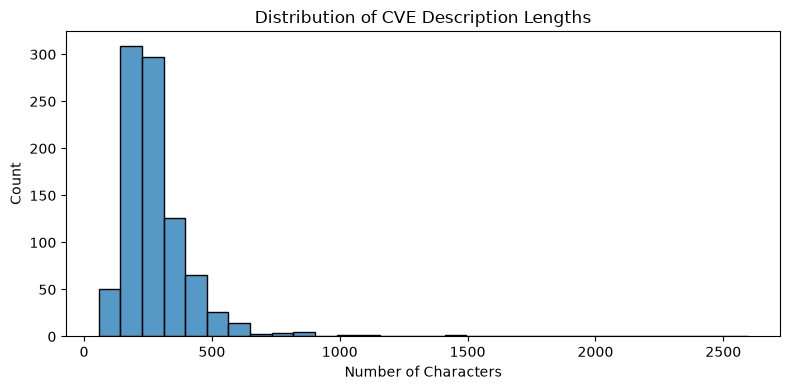

In [6]:

import seaborn as sns
import matplotlib.pyplot as plt

# Prepare numerical features for plotting
plot_df = df_eda.copy()
for col in ["description_length", "word_count", "publication_year"]:
    plot_df[col] = pd.to_numeric(
        plot_df[col], errors="coerce"
    ).astype("float64")

# 1. Histogram: Description lengths
plt.figure(figsize=(8, 4))
sns.histplot(data=plot_df, x="description_length", bins=30)
plt.title("Distribution of CVE Description Lengths")
plt.xlabel("Number of Characters")
plt.tight_layout()
plt.show()

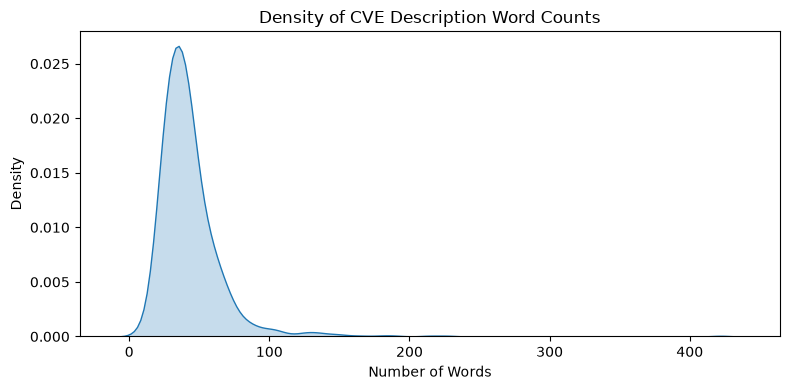

In [7]:
# 2. KDE: Word count distribution
plt.figure(figsize=(8, 4))
sns.kdeplot(data=plot_df, x="word_count", fill=True)
plt.title("Density of CVE Description Word Counts")
plt.xlabel("Number of Words")
plt.tight_layout()
plt.show()

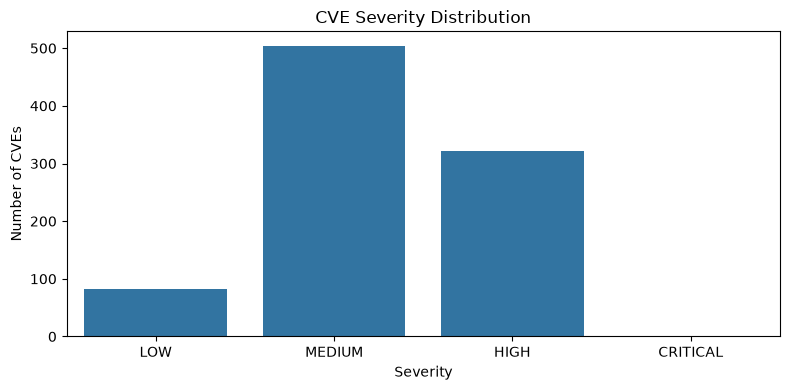

In [8]:
# 3. Count plot: Severity categories
plt.figure(figsize=(8, 4))
sns.countplot(
    data=plot_df,
    x="severity",
    order=["LOW", "MEDIUM", "HIGH", "CRITICAL"]
)
plt.title("CVE Severity Distribution")
plt.xlabel("Severity")
plt.ylabel("Number of CVEs")
plt.tight_layout()
plt.show()

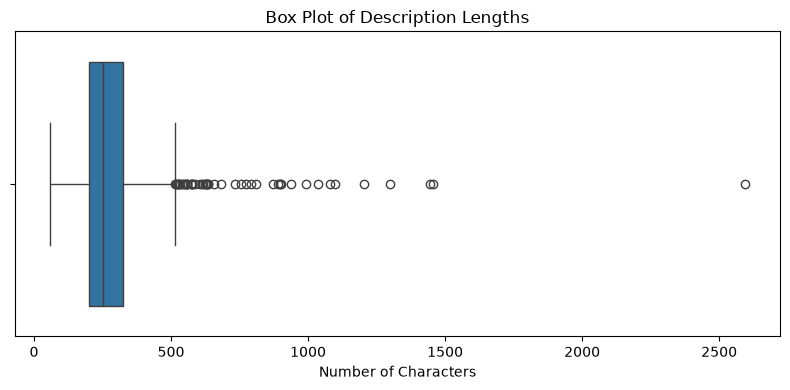

In [9]:
# 4. Box plot: Description lengths
plt.figure(figsize=(8, 4))
sns.boxplot(data=plot_df, x="description_length")
plt.title("Box Plot of Description Lengths")
plt.xlabel("Number of Characters")
plt.tight_layout()
plt.show()

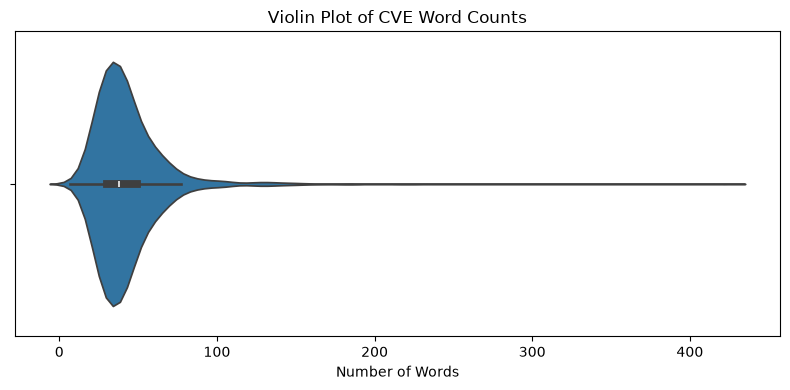

In [10]:
# 5. Violin plot: Word counts
plt.figure(figsize=(8, 4))
sns.violinplot(data=plot_df, x="word_count")
plt.title("Violin Plot of CVE Word Counts")
plt.xlabel("Number of Words")
plt.tight_layout()
plt.show()

## My Interpretation on Single-Feature Visualizations

The histogram shows that vulnerability description lengths are positively skewed. Most descriptions contain approximately 100–400 characters, while a small number are considerably longer.

The KDE plot shows a similar pattern for word counts, with most descriptions containing relatively few words and a long tail extending toward higher counts.

The count plot reveals an imbalanced severity distribution. Medium vulnerabilities represent the largest group (504), followed by High (322) and Low (83). No Critical vulnerabilities were present in the sample.

The box plot identifies several potential outliers in description length, with the longest description containing 2,595 characters. These observations require further investigation before deciding whether they should be removed.

Finally, the violin plot confirms that word counts are concentrated toward lower values, with relatively few descriptions containing very large numbers of words.

Overall, the visualizations indicate right-skewed textual features, potential outliers, and imbalanced severity categories.

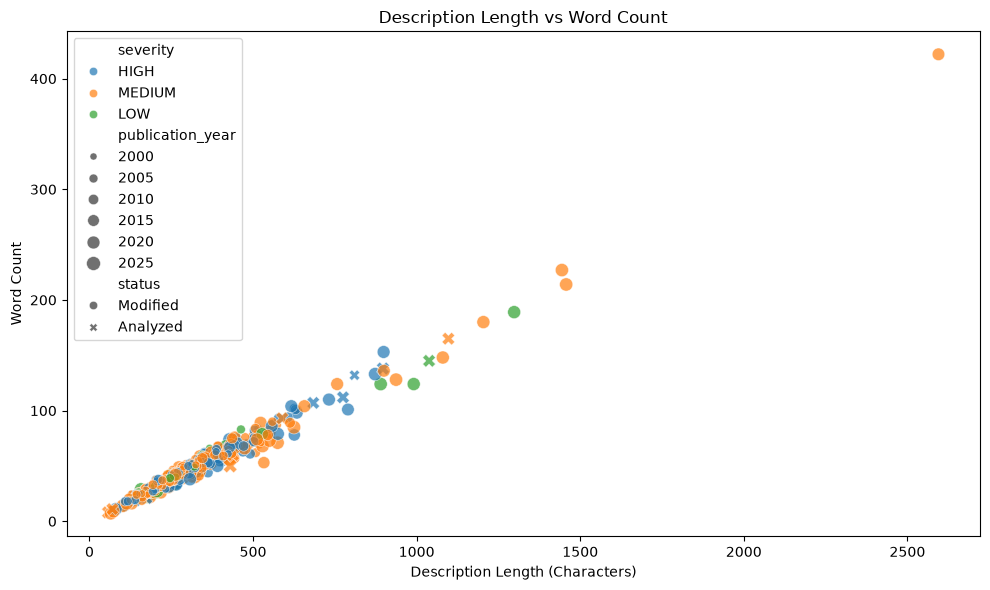

In [11]:
# scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="description_length",
    y="word_count",
    hue="severity",
    style="status",
    size="publication_year",
    sizes=(20, 100),
    alpha=0.7
)

plt.title("Description Length vs Word Count")
plt.xlabel("Description Length (Characters)")
plt.ylabel("Word Count")
plt.tight_layout()
plt.show()

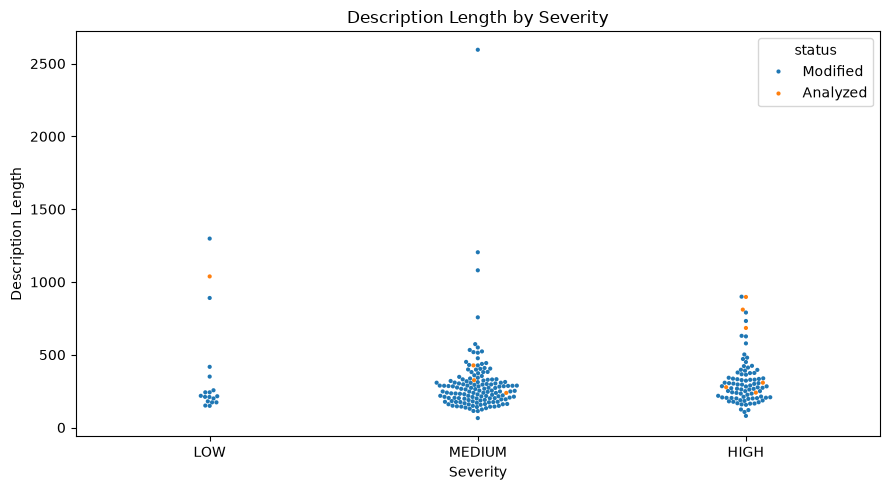

In [12]:
# Swarm plot

# Use a smaller sample to prevent excessive marker overlap
swarm_sample = plot_df.sample(
    n=min(250, len(plot_df)),
    random_state=42
)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_sample,
    x="severity",
    y="description_length",
    hue="status",
    order=["LOW", "MEDIUM", "HIGH"],
    size=3
)

plt.title("Description Length by Severity")
plt.xlabel("Severity")
plt.ylabel("Description Length")
plt.tight_layout()
plt.show()

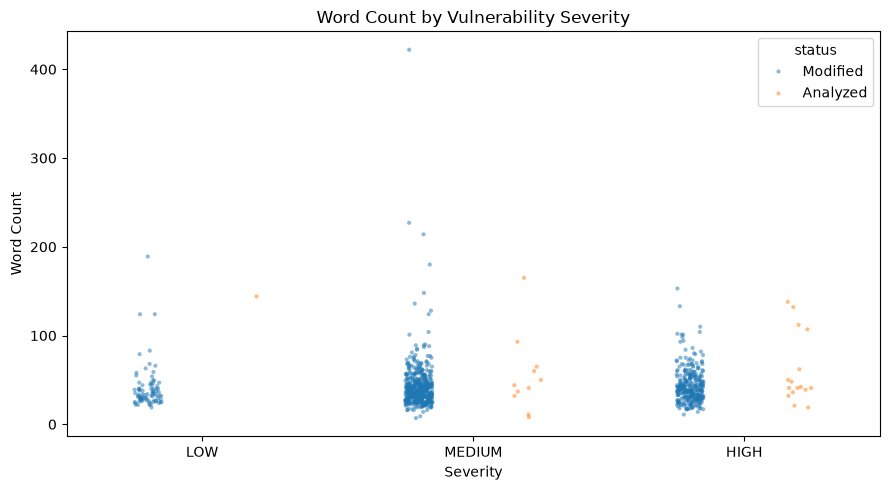

In [13]:
# Strip plot

plt.figure(figsize=(9, 5))

sns.stripplot(
    data=plot_df,
    x="severity",
    y="word_count",
    hue="status",
    order=["LOW", "MEDIUM", "HIGH"],
    jitter=True,
    dodge=True,
    alpha=0.5,
    size=3
)

plt.title("Word Count by Vulnerability Severity")
plt.xlabel("Severity")
plt.ylabel("Word Count")
plt.tight_layout()
plt.show()

## My Interpretation on Two-Feature Visualizations

The scatter plot shows a strong positive relationship between vulnerability description length and word count. As description length increases, word count generally increases as well. Severity categories overlap substantially, suggesting that these textual features alone may have limited ability to distinguish vulnerability severity.

The swarm plot shows that most vulnerabilities have relatively short descriptions regardless of severity. Several unusually long descriptions are visible, particularly in the Medium category. These observations may represent legitimate detailed vulnerability reports rather than incorrect data.

The strip plot shows similar word-count distributions across the three severity categories, although some vulnerabilities have exceptionally high word counts. The distributions overlap considerably, suggesting that description length and word count alone may not be strong predictors of vulnerability severity.

Overall, these plots reveal strong relationships between textual features and highlight potential outliers requiring further investigation.

## 4. Correlation and Distribution Analysis

Pearson Correlation Matrix:


,description_length,word_count,publication_year,days_to_last_modified
description_length,1.000,0.988,0.391,-0.392
word_count,0.988,1.000,0.353,-0.355
publication_year,0.391,0.353,1.000,-0.999
days_to_last_modified,-0.392,-0.355,-0.999,1.000


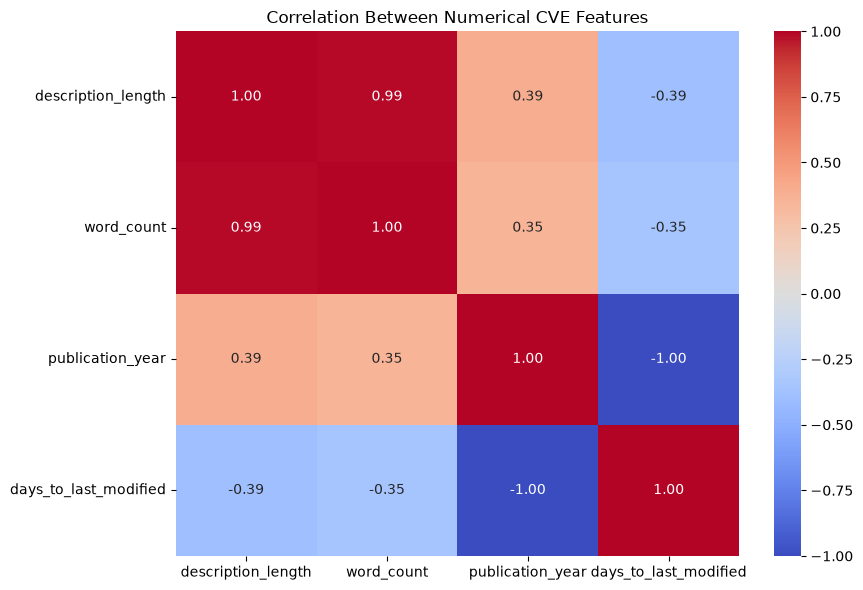


Feature Skewness:


description_length       5.064
word_count               5.563
publication_year         1.012
days_to_last_modified   -1.017
dtype: float64

In [14]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numerical_features = [
    "description_length",
    "word_count",
    "publication_year",
    "days_to_last_modified"
]

# Select numerical features
numeric_df = (
    df_eda[numerical_features]
    .apply(pd.to_numeric, errors="coerce")
    .astype(float)
)

# Calculate Pearson correlation
correlation_matrix = numeric_df.corr()

print("Pearson Correlation Matrix:")
display(correlation_matrix.round(3))

# Visualize correlations
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between Numerical CVE Features")
plt.tight_layout()
plt.show()

# Check distribution skewness
print("\nFeature Skewness:")
display(numeric_df.skew().round(3))


## my Interpretation on Correlation Analysis

The Pearson correlation matrix reveals several relationships among the numerical features.

Description length and word count have a very strong positive correlation (r = 0.99), indicating that longer vulnerability descriptions generally contain more words. These features may provide redundant information in machine learning models.

Publication year and days to last modified show an almost perfect negative correlation (r ≈ -1.00). This relationship is largely explained by the calculation of elapsed time and the concentration of modification timestamps in 2026.

Publication year has moderate positive correlations with description length (r = 0.39) and word count (r = 0.35). This suggests that more recently published vulnerabilities tend to have somewhat longer descriptions in this dataset.

Overall, the correlation analysis reveals potential feature redundancy and relationships influenced by how temporal features were constructed. These findings will inform future feature selection and model development.

## 5. Additional Numerical Feature Visualizations

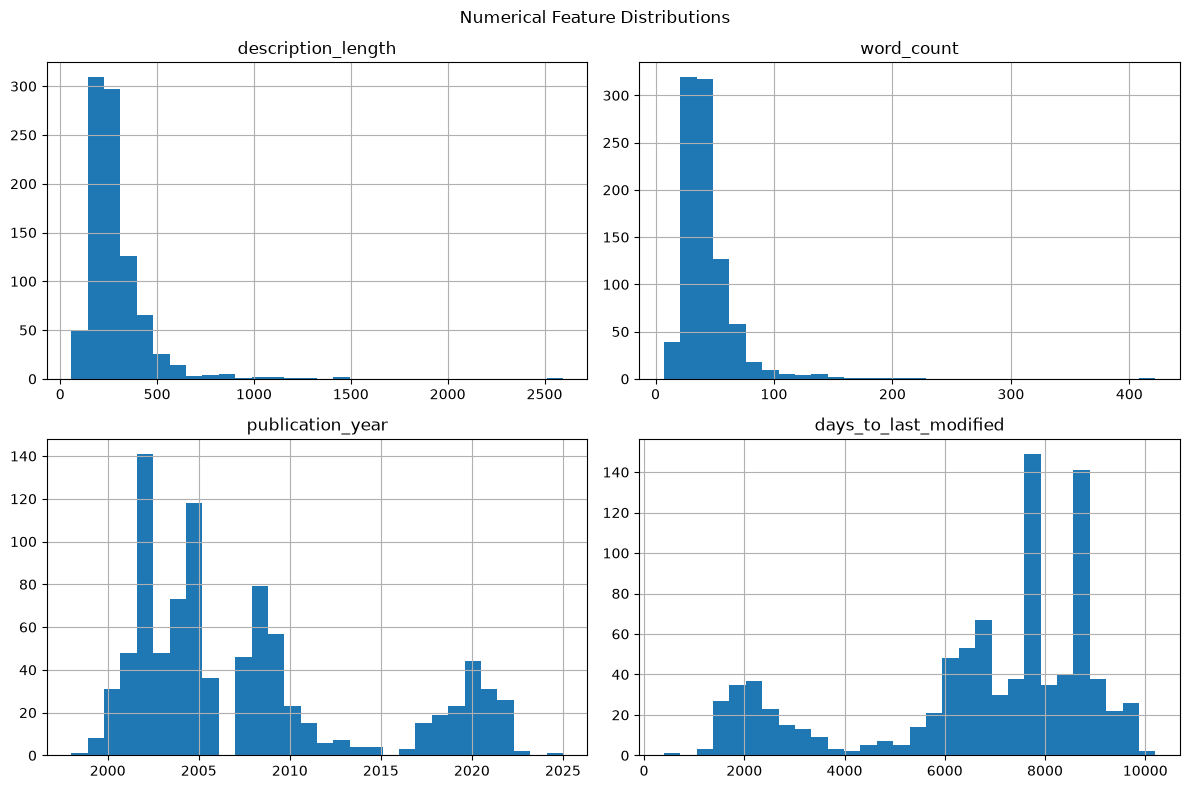

In [15]:
from pandas.plotting import scatter_matrix
import matplotlib.pyplot as plt

# 1. Histograms
numeric_df.hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()





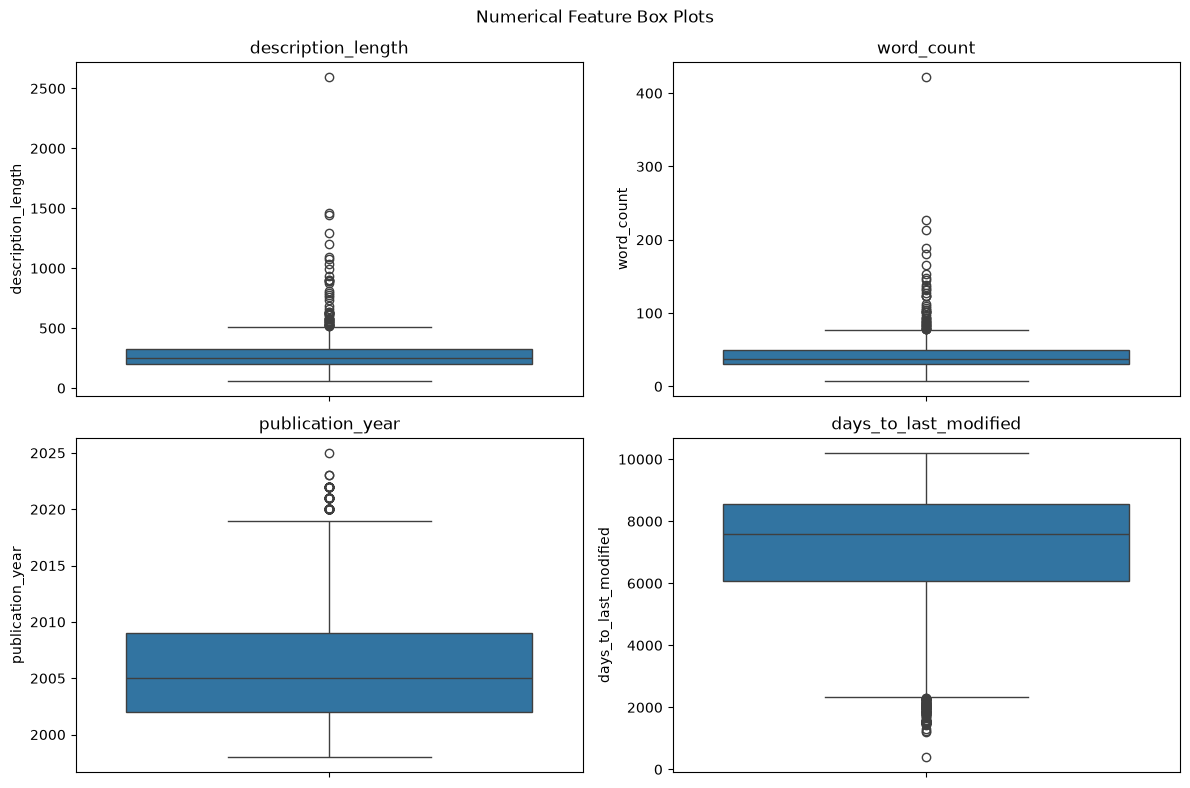

In [16]:

# 2. Box plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flat, numeric_df.columns):
    sns.boxplot(
        y=numeric_df[column].dropna(),
        ax=ax
    )
    ax.set_title(column)
    ax.set_ylabel(column)

fig.suptitle("Numerical Feature Box Plots")
plt.tight_layout()
plt.show()


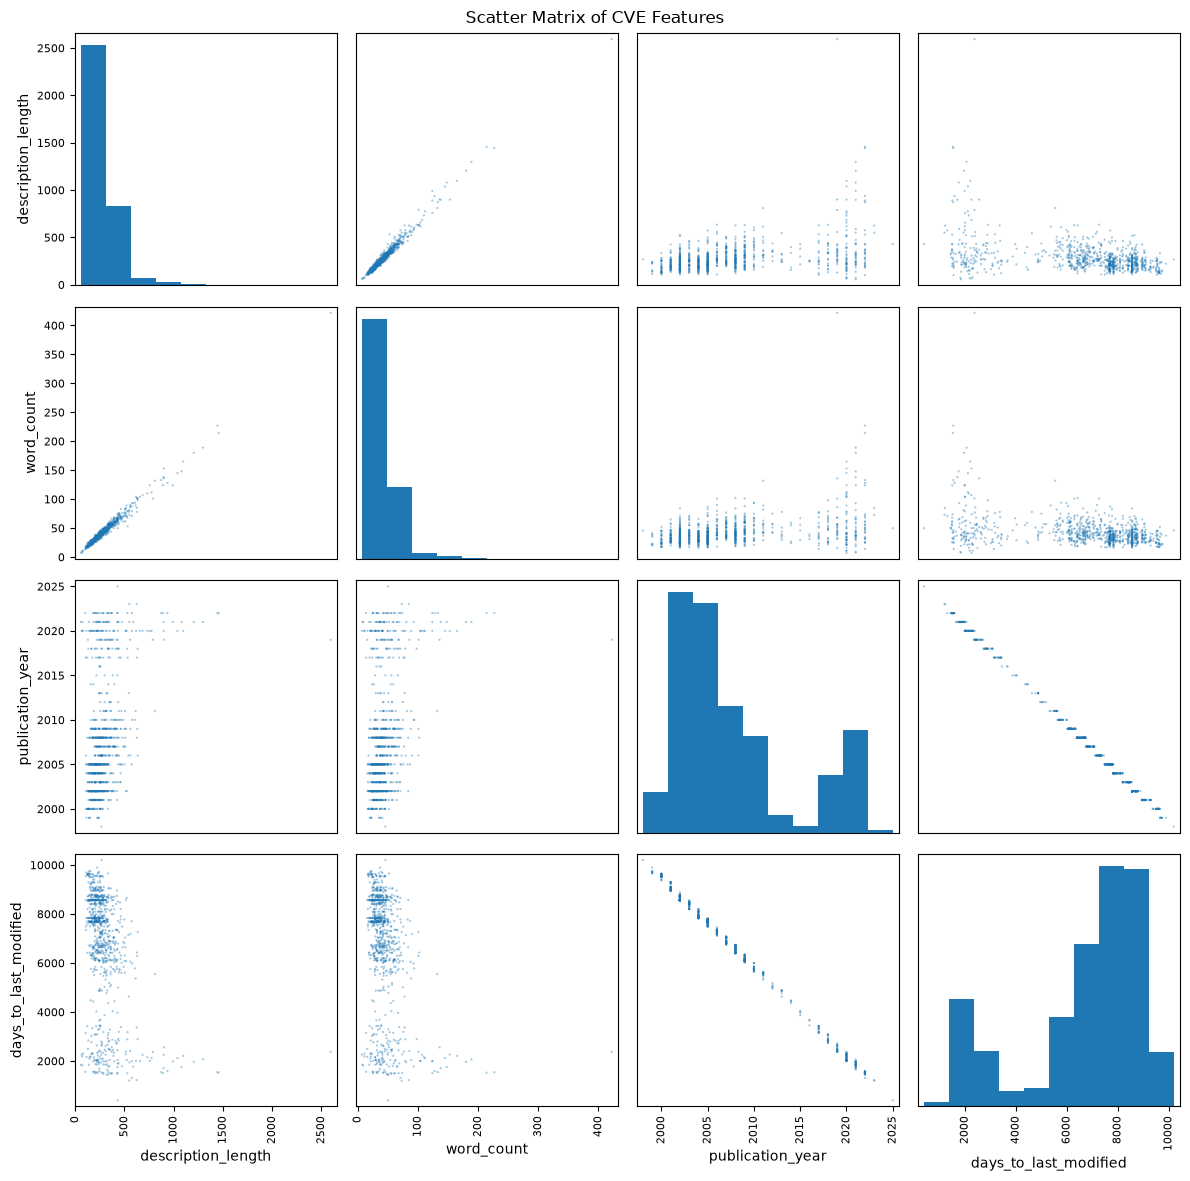

In [17]:
# 3. Scatter matrix
scatter_matrix(
    numeric_df,
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.4,
    s=10
)

plt.suptitle("Scatter Matrix of CVE Features")
plt.tight_layout()
plt.show()

## 6. Outlier Detection and Cleaning

In [18]:
import pandas as pd

# Numerical features to examine
features = ["description_length", "word_count"]

outlier_df = df_eda.copy()
outlier_summary = []

for feature in features:
    values = pd.to_numeric(outlier_df[feature], errors="coerce")

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    flag = (values < lower) | (values > upper)

    outlier_df[f"{feature}_outlier"] = flag.fillna(False)

    outlier_summary.append({
        "Feature": feature,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(flag.sum()),
        "Outlier %": round(flag.mean() * 100, 2)
    })

summary = pd.DataFrame(outlier_summary)

display(summary)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,description_length,10.0,514.0,50,5.50
1,word_count,1.5,77.5,47,5.17


In [19]:
# Find unusually long descriptions
outliers = outlier_df[
    outlier_df["description_length_outlier"]
]

display(
    outliers[
        [
            "cve_id",
            "severity",
            "description_length",
            "word_count",
            "description"
        ]
    ].sort_values(
        "description_length",
        ascending=False
    ).head(10)
)

,cve_id,severity,description_length,word_count,description
815,CVE-2019-13945,MEDIUM,2595,422,Se ha identificado una vulnerabilidad en la fa...
449,CVE-2022-24765,MEDIUM,1457,214,Git para Windows es un fork de Git que contien...
432,CVE-2022-24730,MEDIUM,1444,227,"Argo CD is a declarative, GitOps continuous de..."
440,CVE-2021-21290,LOW,1298,189,"Netty is an open-source, asynchronous event-dr..."
448,CVE-2021-21272,MEDIUM,1204,180,ORAS is open source software which enables a w...
891,CVE-2020-3452,MEDIUM,1097,165,Una vulnerabilidad en la interfaz de servicios...
158,CVE-2021-39155,MEDIUM,1080,148,Istio is an open source platform for providing...
67,CVE-2020-3580,LOW,1038,145,Múltiples vulnerabilidades en la interfaz de s...
160,CVE-2021-3011,LOW,991,124,Se detectó un problema de canal lateral de ond...
355,CVE-2022-23607,MEDIUM,937,128,treq is an HTTP library inspired by requests b...


In [20]:
# Create alternative capped numerical features
df_capped = outlier_df.copy()

for feature in features:
    values = pd.to_numeric(
        df_capped[feature], errors="coerce"
    )

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_capped[f"{feature}_capped"] = (
        values.clip(lower=lower, upper=upper)
    )

print("Original rows:", len(outlier_df))
print("Rows after capping:", len(df_capped))

display(
    df_capped[
        [
            "description_length",
            "description_length_capped",
            "word_count",
            "word_count_capped"
        ]
    ].describe()
)

Original rows: 909
Rows after capping: 909


,description_length,description_length_capped,word_count,word_count_capped
count,909.0,909.0,909.000000,909.000000
mean,285.514851,271.062706,43.300330,41.120462
std,167.844599,102.971145,25.616216,15.546384
min,57.0,57.0,7.000000,7.000000
25%,199.0,199.0,30.000000,30.000000
50%,250.0,250.0,38.000000,38.000000
75%,325.0,325.0,49.000000,49.000000
max,2595.0,514.0,422.000000,77.500000


## My Interpretation of Outlier Detection

The Interquartile Range (IQR) method was applied to vulnerability description length and word count to identify potential outliers.

Both features have right-skewed distributions, indicating that most vulnerabilities have relatively short descriptions, while some contain significantly more detailed information.

The identified outliers may represent legitimate vulnerability descriptions rather than data entry errors. Therefore, removing them without further investigation could result in information loss.

As an alternative treatment, numerical feature capping was demonstrated using IQR boundaries. This approach reduces the influence of extreme numerical values without removing CVE records or altering their original textual descriptions.

The original dataset was preserved for future analysis and machine learning experiments.